# Лабораторная работа 3

## Вариант 11

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from nm.approximation import (
    divided_differences,
    evaluate_cubic_spline,
    interpolation_actual_error,
    interpolation_aposteriori_error_estimate,
    interpolation_apriori_error_bound,
    lagrange_polynomial,
    squared_error_sum,
    least_squares_polynomial,
    least_squares_normal_system,
    natural_cubic_spline_coefficients,
    newton_polynomial,
    rectangle_error_bound,
    rectangle_rule,
    runge_romberg_error,
    simpson_error_bound,
    simpson_rule,
    trapezoidal_error_bound,
    trapezoidal_rule,
)

# 3.1. Интерполяционные многочлены Лагранжа и Ньютона

Дано: $y = arcctg(x)$, $X^* = -0.5$.

Узлы интерполяции:

- a) $X_i = -3, -1, 1, 3$;
- б) $X_i = -3, 0, 1, 3$.

Здесь используется ветвь $arcctg(x) = \frac{\pi}{2} - arctg(x)$.

In [2]:
def arcctg(x):
    return np.pi / 2 - np.arctan(x)


def arcctg_fourth_derivative(x):
    return 24 * x * (x ** 2 - 1) / (1 + x ** 2) ** 4


x_star = -0.5
interpolation_nodes = {
    "a": np.array([-3.0, -1.0, 1.0, 3.0]),
    "б": np.array([-3.0, 0.0, 1.0, 3.0]),
}
extra_nodes = {
    "a": 0.0,
    "б": -1.0,
}

for label, x_nodes in interpolation_nodes.items():
    y_nodes = arcctg(x_nodes)
    lagrange = lagrange_polynomial(x_nodes, y_nodes)
    newton = newton_polynomial(x_nodes, y_nodes)
    differences = divided_differences(x_nodes, y_nodes)

    interpolated = lagrange(x_star)
    real_value = arcctg(x_star)
    actual_error = interpolation_actual_error(arcctg, lagrange, x_star)
    apriori_error = interpolation_apriori_error_bound(
        x_nodes,
        x_star,
        derivative=arcctg_fourth_derivative,
    )
    extra_x = extra_nodes[label]
    aposteriori_error = interpolation_aposteriori_error_estimate(
        x_nodes,
        y_nodes,
        x_star,
        extra_x=extra_x,
        extra_y=arcctg(extra_x),
    )

    print(f"Вариант {label}")
    print("Xi:", x_nodes)
    print("Yi:", y_nodes)
    print("Разделенные разности:", differences)
    print("Многочлен Лагранжа:")
    print(lagrange)
    print("Многочлен Ньютона, приведенный к стандартному виду:")
    print(newton)
    print(f"P(X*) = {interpolated:.10f}")
    print(f"f(X*) = {real_value:.10f}")
    print(f"Фактическая ошибка |f(X*) - P(X*)| = {actual_error:.10f}")
    print(f"Априорная оценка ошибки = {apriori_error:.10f}")
    print(f"Апостериорная оценка по первому отброшенному члену = {aposteriori_error:.10e}")
    print()

    assert np.allclose(lagrange.coeffs, newton.coeffs)

Вариант a
Xi: [-3. -1.  1.  3.]
Yi: [2.8198421  2.35619449 0.78539816 0.32175055]
Разделенные разности: [ 2.8198421  -0.2318238  -0.13839359  0.0461312 ]
Многочлен Лагранжа:
         3
0.04613 x - 0.8315 x + 1.571
Многочлен Ньютона, приведенный к стандартному виду:
         3
0.04613 x - 0.8315 x + 1.571
P(X*) = 1.9807946072
f(X*) = 2.0344439358
Фактическая ошибка |f(X*) - P(X*)| = 0.0536493286
Априорная оценка ошибки = 1.2765591774
Апостериорная оценка по первому отброшенному члену = 4.5536491244e-17

Вариант б
Xi: [-3.  0.  1.  3.]
Yi: [2.8198421  1.57079633 0.78539816 0.32175055]
Разделенные разности: [ 2.8198421  -0.41634859 -0.09226239  0.0461312 ]
Многочлен Лагранжа:
         3
0.04613 x - 0.8315 x + 1.571
Многочлен Ньютона, приведенный к стандартному виду:
         3
0.04613 x - 0.8315 x + 1.571
P(X*) = 1.9807946072
f(X*) = 2.0344439358
Фактическая ошибка |f(X*) - P(X*)| = 0.0536493286
Априорная оценка ошибки = 1.2765591774
Апостериорная оценка по первому отброшенному члену = 2.

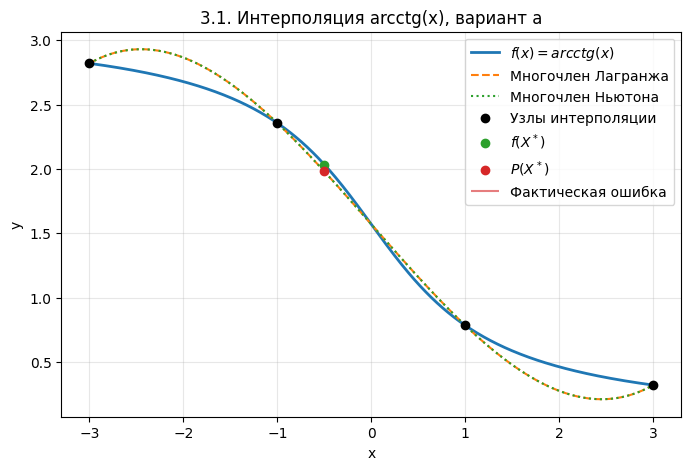

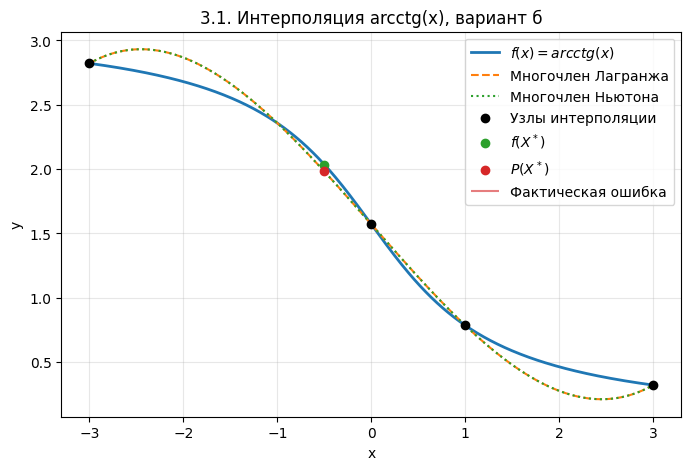

In [3]:
for label, x_nodes in interpolation_nodes.items():
    y_nodes = arcctg(x_nodes)
    lagrange = lagrange_polynomial(x_nodes, y_nodes)
    newton = newton_polynomial(x_nodes, y_nodes)
    grid = np.linspace(np.min(x_nodes), np.max(x_nodes), 400)

    plt.figure(figsize=(8, 5))
    plt.plot(grid, arcctg(grid), label="$f(x) = arcctg(x)$", linewidth=2)
    plt.plot(grid, lagrange(grid), "--", label="Многочлен Лагранжа")
    plt.plot(grid, newton(grid), ":", label="Многочлен Ньютона")
    plt.scatter(x_nodes, y_nodes, color="black", zorder=3, label="Узлы интерполяции")
    plt.scatter([x_star], [arcctg(x_star)], color="tab:green", zorder=4, label="$f(X^*)$")
    plt.scatter([x_star], [lagrange(x_star)], color="tab:red", zorder=4, label="$P(X^*)$")
    plt.vlines(
        x_star,
        ymin=min(arcctg(x_star), lagrange(x_star)),
        ymax=max(arcctg(x_star), lagrange(x_star)),
        color="tab:red",
        alpha=0.6,
        label="Фактическая ошибка",
    )
    plt.title(f"3.1. Интерполяция arcctg(x), вариант {label}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


Априорная оценка вычисляется по формуле $\frac{M_{n+1}}{(n+1)!}|\omega_{n+1}(X^*)|$ при переданной производной нужного порядка.

Апостериорная оценка ниже считается по первому отброшенному члену многочлена Ньютона с дополнительным узлом из альтернативного набора. Для 11-го варианта эта оценка получается практически нулевой из-за нулевой разделенной разности следующего порядка, поэтому фактическая ошибка выводится отдельно.

# 3.2. Кубический сплайн

Построить кубический сплайн по таблице, считая, что кривизна равна нулю при $x = x_0$ и $x = x_4$.

$X^* = -0.5$.

| i | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| $x_i$ | -3.0 | -1.0 | 1.0 | 3.0 | 5.0 |
| $f_i$ | 2.8198 | 2.3562 | 0.78540 | 0.32175 | 0.19740 |


Коэффициенты $c_i$ находятся из трёхдиагональной системы методом прогонки из первой лабораторной работы.


In [4]:
spline_x = np.array([-3.0, -1.0, 1.0, 3.0, 5.0])
spline_y = np.array([2.8198, 2.3562, 0.78540, 0.32175, 0.19740])

coefficients = natural_cubic_spline_coefficients(spline_x, spline_y)
a, b, c, d = coefficients

print("Коэффициенты S_i(x) = a_i + b_i(x - x_i) + c_i(x - x_i)^2 + d_i(x - x_i)^3")
for i in range(len(a)):
    print(
        f"[{spline_x[i]}, {spline_x[i + 1]}]: "
        f"a={a[i]:.10f}, b={b[i]:.10f}, c={c[i]:.10f}, d={d[i]:.10f}"
    )

spline_value = evaluate_cubic_spline(spline_x, coefficients, x_star)
print(f"S({x_star}) = {spline_value:.10f}")

Коэффициенты S_i(x) = a_i + b_i(x - x_i) + c_i(x - x_i)^2 + d_i(x - x_i)^3
[-3.0, -1.0]: a=2.8198000000, b=-0.0470026786, c=0.0000000000, d=-0.0461993304
[-1.0, 1.0]: a=2.3562000000, b=-0.6013946429, c=-0.2771959821, d=0.0925966518
[1.0, 3.0]: a=0.7854000000, b=-0.5990187500, c=0.2783839286, d=-0.0473935268
[3.0, 5.0]: a=0.3217500000, b=-0.0542053571, c=-0.0059772321, d=0.0009962054
S(-0.5) = 1.9977782645


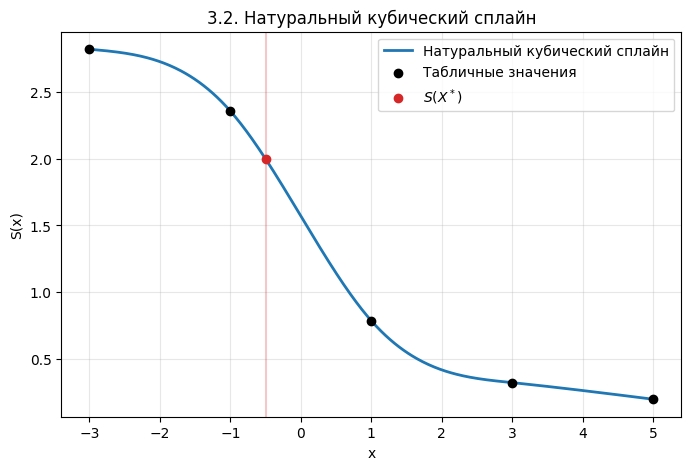

In [5]:
spline_grid = np.linspace(spline_x[0], spline_x[-1], 500)
spline_values = np.array([evaluate_cubic_spline(spline_x, coefficients, x) for x in spline_grid])

plt.figure(figsize=(8, 5))
plt.plot(spline_grid, spline_values, label="Натуральный кубический сплайн", linewidth=2)
plt.scatter(spline_x, spline_y, color="black", zorder=3, label="Табличные значения")
plt.scatter([x_star], [spline_value], color="tab:red", zorder=4, label="$S(X^*)$")
plt.axvline(x_star, color="tab:red", alpha=0.25)
plt.title("3.2. Натуральный кубический сплайн")
plt.xlabel("x")
plt.ylabel("S(x)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# 3.3. Метод наименьших квадратов

Из-за симметрии узлов и значений 11-го варианта выполняется почти точное соотношение $y(-x) + y(x) \approx \pi$. Поэтому квадратичный коэффициент получается почти нулевым, а многочлены первой и второй степени на общем графике практически совпадают.

Дополнительно для проверки построим многочлен третьей степени: он добавляет нечётный кубический член и должен заметно уменьшить сумму квадратов ошибок.

Для таблично заданной функции нужно через нормальную систему МНК найти приближающие многочлены первой и второй степени, посчитать суммы квадратов ошибок и построить графики.

| i | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| $x_i$ | -5.0 | -3.0 | -1.0 | 1.0 | 3.0 | 5.0 |
| $y_i$ | 2.9442 | 2.8198 | 2.3562 | 0.7854 | 0.32175 | 0.1974 |


In [6]:
ls_x = np.array([-5.0, -3.0, -1.0, 1.0, 3.0, 5.0])
ls_y = np.array([2.9442, 2.8198, 2.3562, 0.7854, 0.32175, 0.1974])

SHOW_MATRIX = False
least_squares_results = {}
for degree in (1, 2, 3):
    normal_matrix, right_side = least_squares_normal_system(ls_x, ls_y, degree)
    polynomial = least_squares_polynomial(ls_x, ls_y, degree)
    error_sum = squared_error_sum(polynomial, ls_x, ls_y)
    least_squares_results[degree] = polynomial, error_sum

    print(f"Многочлен степени {degree}")
    if SHOW_MATRIX:
        print("Матрица нормальной системы:")
        print(normal_matrix)
        print("Правая часть:")
        print(right_side)
    print("Коэффициенты по убыванию степеней:")
    print(polynomial.coeffs)
    print("Приближающий многочлен:")
    print(polynomial)
    print(f"Сумма квадратов ошибок: {error_sum:.10f}")
    print()


Многочлен степени 1
Коэффициенты по убыванию степеней:
[-0.32569929  1.57079167]
Приближающий многочлен:
 
-0.3257 x + 1.571
Сумма квадратов ошибок: 0.7006866120

Многочлен степени 2
Коэффициенты по убыванию степеней:
[ 2.23214286e-07 -3.25699286e-01  1.57078906e+00]
Приближающий многочлен:
           2
2.232e-07 x - 0.3257 x + 1.571
Сумма квадратов ошибок: 0.7006866120

Многочлен степени 3
Коэффициенты по убыванию степеней:
[ 1.16152199e-02  2.23214286e-07 -5.60326728e-01  1.57078906e+00]
Приближающий многочлен:
         3             2
0.01162 x + 2.232e-07 x - 0.5603 x + 1.571
Сумма квадратов ошибок: 0.1411740353



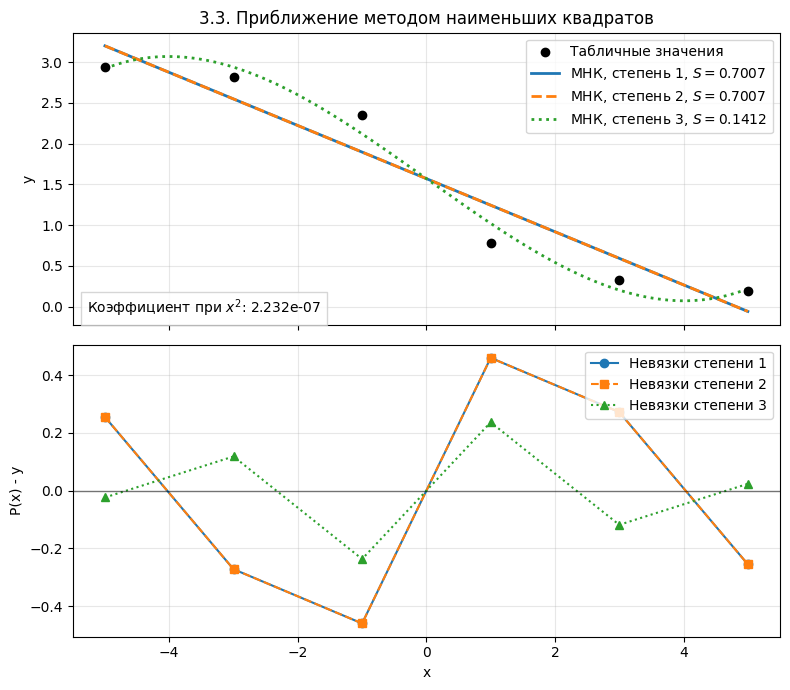

In [7]:
ls_grid = np.linspace(ls_x[0], ls_x[-1], 500)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
ax_fit, ax_residuals = axes

ax_fit.scatter(ls_x, ls_y, color="black", zorder=3, label="Табличные значения")
line_styles = {1: "-", 2: "--", 3: ":"}
markers = {1: "o", 2: "s", 3: "^"}
for degree, (polynomial, error_sum) in least_squares_results.items():
    fitted_grid = polynomial(ls_grid)
    residuals = polynomial(ls_x) - ls_y
    ax_fit.plot(
        ls_grid,
        fitted_grid,
        linestyle=line_styles[degree],
        label=f"МНК, степень {degree}, $S = {error_sum:.4f}$",
        linewidth=2,
    )
    ax_residuals.plot(
        ls_x,
        residuals,
        marker=markers[degree],
        linestyle=line_styles[degree],
        label=f"Невязки степени {degree}",
    )

quadratic = least_squares_results[2][0]
ax_fit.text(
    0.02,
    0.04,
    f"Коэффициент при $x^2$: {quadratic.coeffs[0]:.3e}",
    transform=ax_fit.transAxes,
    bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "0.8"},
)

ax_fit.set_title("3.3. Приближение методом наименьших квадратов")
ax_fit.set_ylabel("y")
ax_fit.grid(True, alpha=0.3)
ax_fit.legend()

ax_residuals.axhline(0, color="black", linewidth=1, alpha=0.5)
ax_residuals.set_xlabel("x")
ax_residuals.set_ylabel("P(x) - y")
ax_residuals.grid(True, alpha=0.3)
ax_residuals.legend()

plt.tight_layout()
plt.show()


Итоговые контрольные значения:

- для 3.1: $P(-0.5) \approx 1.9807946072$, $f(-0.5) \approx 2.0344439358$, фактическая погрешность $\approx 0.0536493286$;
- для 3.2: $S(-0.5) \approx 1.9977782645$.
- для 3.3: $P_1(x) \approx -0.3256992857x + 1.5707916667$, $P_2(x) \approx 0.0000002232x^2 - 0.3256992857x + 1.5707890625$, $S_1 \approx S_2 \approx 0.7006866120$; дополнительно $P_3(x) \approx 0.0116152199x^3 + 0.0000002232x^2 - 0.5603267280x + 1.5707890625$, $S_3 \approx 0.1411740353$.


# 3.4. Численное дифференцирование

Вычислить первую и вторую производную от таблично заданной функции  
$y_i = f(x_i), \quad i = 0,1,2,3,4$  
в точке $x = X^*$.

**Вариант 11.** $X^* = 1.0$

| $i$ | 0     | 1      | 2      | 3      | 4      |
|--------|-------|--------|--------|--------|--------|
| $x_i$ | 0.0   | 0.5    | 1.0    | 1.5    | 2.0    |
| $y_i$ | 1.0   | 1.3776 | 1.5403 | 1.5707 | 1.5839 |

In [8]:
import numpy as np
from nm.approximation import (
    first_derivative_first_order,
    first_derivative_second_order,
    second_derivative,
)

diff_x = np.array([0.0, 0.5, 1.0, 1.5, 2.0])
diff_y = np.array([1.0, 1.3776, 1.5403, 1.5707, 1.5839])
x_star = 1.0

print("3.4. Численное дифференцирование")
print(f"X* = {x_star}")
print()

left_deriv = first_derivative_first_order(diff_x, diff_y, x_star, direction='left')
print(f"Левосторонняя производная (формула 3.18):")
print(f"y'({x_star}) = (y2 - y1)/(x2 - x1) = ({diff_y[2]} - {diff_y[1]})/({diff_x[2]} - {diff_x[1]}) = {left_deriv:.4f}")
print()

right_deriv = first_derivative_first_order(diff_x, diff_y, x_star, direction='right')
print(f"Правосторонняя производная (формула 3.18):")
print(f"y'({x_star}) = (y3 - y2)/(x3 - x2) = ({diff_y[3]} - {diff_y[2]})/({diff_x[3]} - {diff_x[2]}) = {right_deriv:.4f}")
print()

second_order_deriv = first_derivative_second_order(diff_x, diff_y, x_star)
print(f"Производная второго порядка точности (формула 3.20):")
print(f"y'({x_star}) = {second_order_deriv:.4f}")
print()

second_deriv = second_derivative(diff_x, diff_y, x_star)
print(f"Вторая производная (формула 3.21):")
print(f"y''({x_star}) = {second_deriv:.4f}")


3.4. Численное дифференцирование
X* = 1.0

Левосторонняя производная (формула 3.18):
y'(1.0) = (y2 - y1)/(x2 - x1) = (1.5403 - 1.3776)/(1.0 - 0.5) = 0.3254

Правосторонняя производная (формула 3.18):
y'(1.0) = (y3 - y2)/(x3 - x2) = (1.5707 - 1.5403)/(1.5 - 1.0) = 0.0608

Производная второго порядка точности (формула 3.20):
y'(1.0) = 0.0780

Вторая производная (формула 3.21):
y''(1.0) = -0.0688


# 3.5. Численное интегрирование

Вычислить определенный интеграл

$$F = \int_{x_0}^{x_k} y\,dx$$

методами прямоугольников, трапеций и Симпсона с шагами $h_1$, $h_2$. Оценить погрешность вычислений методом Рунге-Ромберга.

**Вариант 11.**

$$y = \frac{1}{x^3 + 64}, \quad x_0 = -2, \quad x_k = 2, \quad h_1 = 1.0, \quad h_2 = 0.5.$$


<!--Для метода прямоугольников используется составная формула средних прямоугольников из (3.23):

$$I_h = h\sum_{i=0}^{n-1} f\left(\frac{x_i + x_{i+1}}{2}\right).$$

Для трапеций используется формула (3.25), для Симпсона при постоянном шаге — формула (3.28).

Мажорантные оценки остаточного члена из методички:

$$R_{rect} \le \frac{1}{24}h^2M_2(b-a), \quad R_{trap} \le \frac{b-a}{12}h^2M_2, \quad R_{simp} \le \frac{b-a}{180}h^4M_4.$$

Для заданной функции $f(x)=1/(x^3+64)$ на $[-2,2]$ максимумы производных достигаются на левом конце отрезка:

$$M_2 = \max |f^{\prime\prime}(x)| \approx 0.0054664723, \quad M_4 = \max |f^{(4)}(x)| \approx 0.0154288392.$$

Оценка Рунге-Ромберга-Ричардсона из (3.30) для уточнения шага в 2 раза:

$$F \approx I_{h_2} + \frac{I_{h_2} - I_{h_1}}{(h_1 / h_2)^p - 1}.$$

Для прямоугольников и трапеций берем $p = 2$, для метода Симпсона $p = 4$.
-->

In [9]:
def integration_function(x):
    return 1 / (x ** 3 + 64)


integration_left = -2.0
integration_right = 2.0
h1 = 1.0
h2 = 0.5
m2 = 0.0054664723032070
m4 = 0.0154288391741536

integration_methods = {
    "Метод прямоугольников": (rectangle_rule, rectangle_error_bound, m2, 2),
    "Метод трапеций": (trapezoidal_rule, trapezoidal_error_bound, m2, 2),
    "Метод Симпсона": (simpson_rule, simpson_error_bound, m4, 4),
}

integration_results = {}
for name, (method, error_bound, derivative_bound, order) in integration_methods.items():
    value_h1 = method(integration_function, integration_left, integration_right, h1)
    value_h2 = method(integration_function, integration_left, integration_right, h2)
    correction = runge_romberg_error(value_h1, value_h2, h1, h2, order)
    corrected = value_h2 + correction
    bound_h1 = error_bound(integration_left, integration_right, h1, derivative_bound)
    bound_h2 = error_bound(integration_left, integration_right, h2, derivative_bound)
    integration_results[name] = value_h1, value_h2, correction, corrected, bound_h1, bound_h2

    print(name)
    print(f"I(h1={h1}) = {value_h1:.10f}")
    print(f"I(h2={h2}) = {value_h2:.10f}")
    print(f"Мажорантная оценка для h1: {bound_h1:.10f}")
    print(f"Мажорантная оценка для h2: {bound_h2:.10f}")
    print(f"Поправка Рунге-Ромберга: {correction:.10f}")
    print(f"Оценка погрешности по Рунге-Ромбергу: {abs(correction):.10f}")
    print(f"Уточненное значение: {corrected:.10f}")
    print()


Метод прямоугольников
I(h1=1.0) = 0.0625872651
I(h2=0.5) = 0.0626255883
Мажорантная оценка для h1: 0.0009110787
Мажорантная оценка для h2: 0.0002277697
Поправка Рунге-Ромберга: 0.0000127744
Оценка погрешности по Рунге-Ромбергу: 0.0000127744
Уточненное значение: 0.0626383627

Метод трапеций
I(h1=1.0) = 0.0627556471
I(h2=0.5) = 0.0626714561
Мажорантная оценка для h1: 0.0018221574
Мажорантная оценка для h2: 0.0004555394
Поправка Рунге-Ромберга: -0.0000280637
Оценка погрешности по Рунге-Ромбергу: 0.0000280637
Уточненное значение: 0.0626433925

Метод Симпсона
I(h1=1.0) = 0.0626755189
I(h2=0.5) = 0.0626433925
Мажорантная оценка для h1: 0.0003428631
Мажорантная оценка для h2: 0.0000214289
Поправка Рунге-Ромберга: -0.0000021418
Оценка погрешности по Рунге-Ромбергу: 0.0000021418
Уточненное значение: 0.0626412507



Итоговые контрольные значения:

<table>
<tr><th>Метод</th><th>I(h_1)</th><th>I(h_2)</th><th>маж. R(h_2)</th><th>|R_{RR}|</th><th>I(h_2) + R_{RR}</th></tr>
<tr><td>Прямоугольников</td><td>0.0625872651</td><td>0.0626255883</td><td>0.0002277697</td><td>0.0000127744</td><td>0.0626383627</td></tr>
<tr><td>Трапеций</td><td>0.0627556471</td><td>0.0626714561</td><td>0.0004555394</td><td>0.0000280637</td><td>0.0626433925</td></tr>
<tr><td>Симпсона</td><td>0.0626755189</td><td>0.0626433925</td><td>0.0000214289</td><td>0.0000021418</td><td>0.0626412507</td></tr>
</table>